In [7]:
%pip install pandas numpy openpyxl matplotlib seaborn scikit-learn xgboost

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.9 MB 6.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.6/9.9 MB 6.1 MB/s eta 0:00:02
   --------------- ------------------------ 3.9/9.9 MB 5.8 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.9 MB 5.7 MB/s eta 0:00:01
   --------------------------- ------------ 6.8/9.9 MB 6.2 MB/s eta 0:00:01
   -------------------------------- ------- 8.1/9.9 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.9 MB 6.4 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 6.2 MB/s  0:00:01
   ---------------------------------------- 0.0/12.5 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.5 MB 6.7 MB/s eta 0:00:02
   -------- ------------------------------- 2.6/12.5 MB 6.3 MB/s eta 0:00:02
   ------------- -------------------------- 4.2/12.5 MB 6.7 MB/s eta 0:00:02
   ------------------ ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [11]:
import pandas as pd
import numpy as np

# Use read_excel instead of read_csv for .xlsx files
df = pd.read_excel("Online Retail.xlsx")

# Print the dataset size and show the top 5 rows
print(f"Dataset loaded successfully! Total rows: {df.shape[0]}, Total columns: {df.shape[1]}")
df.head()

Dataset loaded successfully! Total rows: 541909, Total columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
# 1. Check for missing data in crucial columns
print("--- Missing Values ---")
print(df.isnull().sum())

# 2. Inspect numerical anomalies (Negative quantities or pricing errors)
print("\n--- Data Distribution Summary ---")
df[['Quantity', 'UnitPrice']].describe()

--- Missing Values ---
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

--- Data Distribution Summary ---


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [13]:
# 1. Drop missing Customer IDs
df_clean = df.dropna(subset=['CustomerID']).copy()

# 2. Ensure CustomerID is stored as an integer (removes trailing decimals like 12345.0)
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# 3. Filter out negative or zero quantities and unit prices
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 4. Create a Total Revenue column for every single transaction row
df_clean['TotalSpend'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Check our progress
print(f"Original dataset rows: {df.shape[0]}")
print(f"Cleaned dataset rows: {df_clean.shape[0]}")
print(f"Rows removed as anomalies: {df.shape[0] - df_clean.shape[0]}")
print("\n--- Cleaned Data Distribution ---")
df_clean[['Quantity', 'UnitPrice', 'TotalSpend']].describe()

Original dataset rows: 541909
Cleaned dataset rows: 397884
Rows removed as anomalies: 144025

--- Cleaned Data Distribution ---


,Quantity,UnitPrice,TotalSpend
count,397884.000000,397884.000000,397884.000000
mean,12.988238,3.116488,22.397000
std,179.331775,22.097877,309.071041
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.680000
50%,6.000000,1.950000,11.800000
75%,12.000000,3.750000,19.800000
max,80995.000000,8142.750000,168469.600000


In [14]:
# 1. Convert InvoiceDate to a proper datetime format so Python can do math with it
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 2. Define our snapshot baseline date (1 day after the absolute latest purchase)
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# 3. Group by CustomerID and aggregate the RFM metrics
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                  # Frequency
    'TotalSpend': 'sum'                                      # Monetary
})

# 4. Rename the columns to be clear and professional
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalSpend': 'Monetary'
}, inplace=True)

# Check our new customer-centric dataset layout
print(f"Total Unique Customers Profiled: {rfm.shape[0]}")
rfm.head()

Total Unique Customers Profiled: 4338


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [15]:
# Check the statistical distribution of our new RFM features
print("--- RFM Distribution Summary ---")
rfm.describe()

--- RFM Distribution Summary ---


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


In [16]:
# 1. Define our target variable: Churn (1 if Recency > 90 days, else 0)
rfm['Churn'] = (rfm['Recency'] > 90).astype(int)

# 2. Apply Log Transformation to handle extreme outliers for ML modeling
rfm['Log_Recency'] = np.log1p(rfm['Recency'])
rfm['Log_Frequency'] = np.log1p(rfm['Frequency'])
rfm['Log_Monetary'] = np.log1p(rfm['Monetary'])

# 3. Check the class balance of our target (How many churned vs active?)
print("--- Target Variable (Churn) Balance ---")
print(rfm['Churn'].value_counts(normalize=True)) # Shows percentages

print("\n--- Transformed Features Preview ---")
rfm[['Log_Recency', 'Log_Frequency', 'Log_Monetary', 'Churn']].head()

--- Target Variable (Churn) Balance ---
Churn
0    0.665975
1    0.334025
Name: proportion, dtype: float64

--- Transformed Features Preview ---


,Log_Recency,Log_Frequency,Log_Monetary,Churn
CustomerID,,,,
12346,5.789960,0.693147,11.253955,1
12347,1.098612,2.079442,8.368925,0
12348,4.330733,1.609438,7.494564,0
12349,2.995732,0.693147,7.472245,0
12350,5.739793,0.693147,5.815324,1


In [17]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Separate our features (X) from our target variable (y)
X = rfm[['Log_Recency', 'Log_Frequency', 'Log_Monetary']]
y = rfm['Churn']

# 2. Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Initialize and train the XGBoost Model
model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
model.fit(X_train, y_train)

# 4. Predict on the unseen test data
y_pred = model.predict(X_test)

# 5. Evaluate the results
print("--- Machine Learning Model Performance ---")
print(classification_report(y_test, y_pred))

--- Machine Learning Model Performance ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       578
           1       1.00      1.00      1.00       290

    accuracy                           1.00       868
   macro avg       1.00      1.00      1.00       868
weighted avg       1.00      1.00      1.00       868



In [18]:
# 1. REMOVE Log_Recency from our features to fix the data leakage!
X_corrected = rfm[['Log_Frequency', 'Log_Monetary']]
y = rfm['Churn']

# 2. Split into 80% Training and 20% Testing sets again
X_train_c, X_test_c, y_train, y_test = train_test_split(
    X_corrected, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Re-train the XGBoost Model on the realistic features
model_corrected = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
model_corrected.fit(X_train_c, y_train)

# 4. Predict on the unseen test data
y_pred_c = model_corrected.predict(X_test_c)

# 5. Evaluate the realistic results
print("--- Realistic Machine Learning Model Performance ---")
print(classification_report(y_test, y_pred_c))

--- Realistic Machine Learning Model Performance ---
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       578
           1       0.61      0.47      0.53       290

    accuracy                           0.72       868
   macro avg       0.69      0.66      0.67       868
weighted avg       0.71      0.72      0.71       868



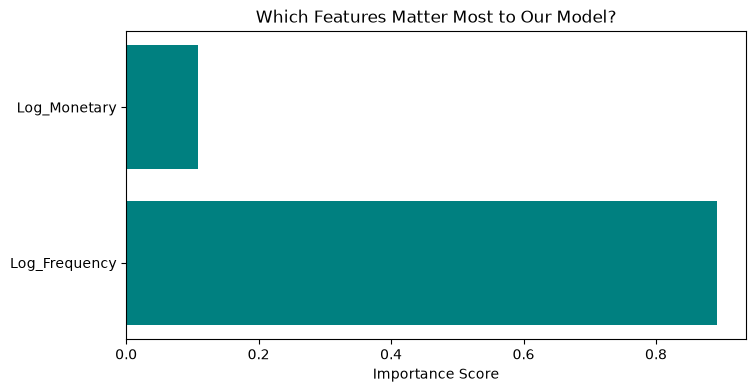

In [19]:
import matplotlib.pyplot as plt

# Get feature importances from our corrected XGBoost model
importances = model_corrected.feature_importances_
features = X_corrected.columns

# Plot the data
plt.figure(figsize=(8, 4))
plt.barh(features, importances, color='teal')
plt.title('Which Features Matter Most to Our Model?')
plt.xlabel('Importance Score')
plt.show()

In [20]:
# Train a tuned model that balances the classes
model_tuned = XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=4, 
    scale_pos_weight=2, # Compels the model to focus heavily on the minority churn class
    random_state=42
)
model_tuned.fit(X_train_c, y_train)

# Predict and evaluate
y_pred_tuned = model_tuned.predict(X_test_c)
print("--- Tuned Machine Learning Model Performance ---")
print(classification_report(y_test, y_pred_tuned))

--- Tuned Machine Learning Model Performance ---
              precision    recall  f1-score   support

           0       0.87      0.61      0.72       578
           1       0.51      0.81      0.63       290

    accuracy                           0.68       868
   macro avg       0.69      0.71      0.67       868
weighted avg       0.75      0.68      0.69       868



In [22]:
# 1. Calculate the exact probability of churn for every customer
# predict_proba returns [prob_of_0, prob_of_1]. We grab index 1 (probability of churning).
rfm['Churn_Probability'] = model_tuned.predict_proba(X_corrected)[:, 1]

# 2. Add our final hard prediction flag (0 or 1) based on our tuned model
rfm['Predicted_Churn_Flag'] = model_tuned.predict(X_corrected)

# 3. Create a clean dataframe with original metrics and new predictions for business use
final_delivery = rfm[['Recency', 'Frequency', 'Monetary', 'Churn_Probability', 'Predicted_Churn_Flag']]

# 4. Export to an Excel file inside your project folder
final_delivery.to_excel("customer_churn_predictions.xlsx")

print(" SPRINT COMPLETE! ")
print("Saved 'customer_churn_predictions.xlsx' successfully in your project folder.")
print(f"Total rows exported: {final_delivery.shape[0]}")
final_delivery.head()

 SPRINT COMPLETE! 
Saved 'customer_churn_predictions.xlsx' successfully in your project folder.
Total rows exported: 4338


,Recency,Frequency,Monetary,Churn_Probability,Predicted_Churn_Flag
CustomerID,,,,,
12346,326,1,77183.60,0.630344,1
12347,2,7,4310.00,0.028095,0
12348,75,4,1797.24,0.217464,0
12349,19,1,1757.55,0.635124,1
12350,310,1,334.40,0.703016,1
